In [2]:

# Import Pandas for loading and handling tabular data
import pandas as pd

# Import Path to manage file paths
from pathlib import Path

# Set the path to the dataset folder
DATA_DIR = Path("../dataset")

# Load the phishing email dataset
data = pd.read_csv(DATA_DIR / "phishing_email.csv")

# Display the dataset dimensions (rows, columns)
print("Dataset shape:", data.shape)

# Display the available column names
print("Columns:", data.columns.tolist())

# Display the first five rows
display(data.head())


Dataset shape: (82486, 2)
Columns: ['text_combined', 'label']


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [3]:

# Check missing values in each column
print("Missing values:")
print(data.isnull().sum())

# Check how many emails belong to each label
print("\nLabel distribution:")
print(data["label"].value_counts())

# Display label proportions as percentages
print("\nLabel percentages:")
print((data["label"].value_counts(normalize=True) * 100).round(2))

# Check the data types of both columns
print("\nColumn data types:")
print(data.dtypes)

# Display one example email from each label
for label in sorted(data["label"].dropna().unique()):
    # Select the first email with this label
    sample = data.loc[data["label"] == label, "text_combined"].iloc[0]

    # Print the label and the first 300 characters
    print(f"\nLabel {label} example:")
    print(sample[:300])


Missing values:
text_combined    0
label            0
dtype: int64

Label distribution:
label
1    42891
0    39595
Name: count, dtype: int64

Label percentages:
label
1    52.0
0    48.0
Name: proportion, dtype: float64

Column data types:
text_combined    object
label             int64
dtype: object

Label 0 example:
hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls

Label 1 example:
link dwl g 510 802 11 g wireless pci lan adapter 39 85 39 85 dwl g 510 high speed 2 4 ghz 802 11 g wireless pci lan adapter ieee 802 11 g standardupto 54 mbpsoperating frequency range 2 4 ghz ideal solution enabling wireless networking capabilities desktops pcs home office dwl g 510 visit http www c


In [4]:

# Check how many exact duplicate rows exist
print("Duplicate rows:", data.duplicated().sum())

# Check whether any labels other than 0 and 1 exist
print("Unique labels:", sorted(data["label"].unique()))

# Create a working copy of the dataset
emails = data.copy()

# Convert email text to strings and remove extra spaces
emails["text_combined"] = emails["text_combined"].astype(str).str.strip()

# Remove rows where the email text is empty
emails = emails[emails["text_combined"] != ""]

# Display the cleaned dataset size
print("Dataset shape after basic cleaning:", emails.shape)


Duplicate rows: 408
Unique labels: [np.int64(0), np.int64(1)]
Dataset shape after basic cleaning: (82485, 2)


In [5]:

# Import the function used to split the dataset
from sklearn.model_selection import train_test_split

# Separate email text (input) and labels (target)
X = emails["text_combined"]
y = emails["label"]

# Split data into 80% training and 20% testing
# stratify=y preserves the label proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the size of each split
print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

# Display label counts in the training data
print("\nTraining label distribution:")
print(y_train.value_counts())

# Display label counts in the testing data
print("\nTesting label distribution:")
print(y_test.value_counts())


Training emails: 65988
Testing emails: 16497

Training label distribution:
label
1    34312
0    31676
Name: count, dtype: int64

Testing label distribution:
label
1    8578
0    7919
Name: count, dtype: int64


In [6]:

# Import TF-IDF to convert email text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
# Keep the 5000 most important features and ignore common English stop words
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

# Learn vocabulary and convert training emails into numerical features
X_train_tfidf = vectorizer.fit_transform(X_train)

# Convert testing emails using the same vocabulary
X_test_tfidf = vectorizer.transform(X_test)

# Display the shapes of the transformed datasets
print("Training features shape:", X_train_tfidf.shape)
print("Testing features shape:", X_test_tfidf.shape)


Training features shape: (65988, 5000)
Testing features shape: (16497, 5000)


In [7]:

# Import Logistic Regression for email classification
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train the model using TF-IDF features and their labels
model.fit(X_train_tfidf, y_train)

# Display a confirmation message after training
print("Phishing email detection model trained successfully!")

# Display the number of features used by the model
print("Number of features:", X_train_tfidf.shape[1])


Phishing email detection model trained successfully!
Number of features: 5000


In [8]:

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict labels for the testing emails
y_pred = model.predict(X_test_tfidf)

# Calculate and display model accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display precision, recall, and F1-score for both classes
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate Email", "Phishing Email"]
))

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 98.19%

Classification Report:
                  precision    recall  f1-score   support

Legitimate Email       0.98      0.98      0.98      7919
  Phishing Email       0.98      0.98      0.98      8578

        accuracy                           0.98     16497
       macro avg       0.98      0.98      0.98     16497
    weighted avg       0.98      0.98      0.98     16497


Confusion Matrix:
[[7761  158]
 [ 141 8437]]


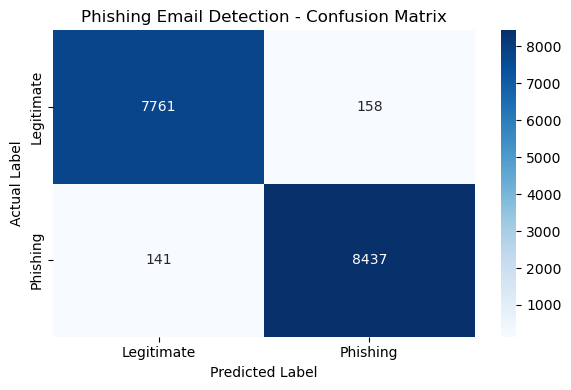

In [9]:

# Import Matplotlib for plotting
import matplotlib.pyplot as plt

# Import Seaborn for the confusion matrix heatmap
import seaborn as sns

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create a figure for the heatmap
plt.figure(figsize=(6, 4))

# Display the confusion matrix with labels and cell values
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

# Add labels and title
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Phishing Email Detection - Confusion Matrix")

# Display the plot
plt.tight_layout()
plt.show()


In [10]:

# Import joblib to save machine learning objects
import joblib

# Import Path to manage folder paths
from pathlib import Path

# Set the path to the models directory
MODEL_DIR = Path("../models")

# Create the models directory if it does not exist
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained Logistic Regression model
joblib.dump(model, MODEL_DIR / "phishing_model.pkl")

# Save the fitted TF-IDF vectorizer
joblib.dump(vectorizer, MODEL_DIR / "tfidf_vectorizer.pkl")

# Display a confirmation message
print("Model and TF-IDF vectorizer saved successfully!")
print("Saved files:", list(MODEL_DIR.iterdir()))


Model and TF-IDF vectorizer saved successfully!
Saved files: [WindowsPath('../models/phishing_model.pkl'), WindowsPath('../models/tfidf_vectorizer.pkl')]
